# Etapa 4. Indexación principal (B+Tree)

**Proyecto EDA 2026-2, Grupo 1, escenario B (comercio electrónico).**
Responsable de las etapas 3, 4 y 5: Carlos.

## Función de la etapa en el pipeline

La etapa 4 resuelve las **consultas por rango** del escenario B, por ejemplo "productos entre 10 y 20 dólares". La tabla hash de la etapa 3 responde consultas puntuales en O(1), pero no conserva el orden de las claves y no sirve para rangos. Un índice ordenado sí lo permite.

La estructura es un **B+Tree en disco** implementado a mano. El árbol vive en un archivo dividido en páginas de tamaño fijo y cada nodo ocupa una página. La clave es `(precio, parent_asin)` y el valor es la posición del registro en el catálogo en disco de la etapa 3. Las páginas leídas se guardan en un buffer pool, que es la caché LRU de la etapa 3. Un archivo ordenado con búsqueda binaria y una lista ordenada en memoria se usan como líneas base.

## Proceso

```
catálogo en disco (etapa 3)                 estado de productos (etapa 3)
   │                                            │
   ├─ 1. extraer (precio, parent_asin, offset, largo) de los productos con precio
   ├─ 2. ordenar con el merge sort de la etapa 1                      O(n log n)
   ├─ 3. carga masiva del B+Tree, página por página                    O(n)
   │                                            │
   │                                            └─ 4. insertar los productos con precio observado en el stream   O(log_B n)
   │
   ├─ consulta puntual: descenso raíz → hoja                           O(log_B n) lecturas
   └─ consulta por rango: descenso + recorrido de hojas enlazadas      O(log_B n + k / B) lecturas
   │
índice de precios en disco (etapas 5 y 9)
```

## Pasos del notebook

1. Configuración y entrada.
2. Estructura del B+Tree en disco.
3. Construcción del índice de precios.
4. Actualización del índice con el stream.
5. Consultas puntuales y por rango.
6. Experimentos de complejidad.
7. Salida de la etapa 4.

El código está en `src/stage4_bplustree.py`. El notebook lo importa y muestra las partes principales.

## Paso 1. Configuración y entrada

La etapa usa dos salidas de la etapa 3 que están en `data/interim/<CATEGORIA>/`.

- `etapa3_catalogo.jsonl`, el catálogo en disco con el precio ya convertido a número.
- `etapa3_estado_productos.parquet`, el estado de los productos con actividad en el stream, que incluye el precio observado en las compras.

In [1]:
import gc
import inspect
import json
import math
import platform
import random
import shutil
import struct
import sys
import time
import tracemalloc
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import pyarrow.parquet as pq

# Raíz del proyecto: se sube de carpeta hasta encontrar la que contiene notebooks/ y data/
RAIZ = Path.cwd()
while not ((RAIZ / "notebooks").is_dir() and (RAIZ / "data").is_dir()) and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))       # para importar src/

from src import config
from src.stage3_storage import RUTA_CATALOGO, AlmacenCatalogo
from src.stage4_bplustree import (RUTA_INDICE_PRECIO, TAM_PAGINA, ArbolBMas, bisect_izq, capacidad_hoja,
                                  capacidad_interno, clave, construir_indice_precio, entradas_catalogo,
                                  leer_registro)

SEED = config.SEED
CATEGORIA = config.CATEGORIA
CARPETA_INTERIM = config.CARPETA_INTERIM
CARPETA_RESULTADOS = config.CARPETA_RESULTADOS
CARPETA_RESULTADOS.mkdir(exist_ok=True)
RUTA_ESTADOS = CARPETA_INTERIM / "etapa3_estado_productos.parquet"
assert RUTA_CATALOGO.exists() and RUTA_ESTADOS.exists(), \
    "Falta la salida de la etapa 3. Ejecutar antes notebooks/etapa3_almacenamiento_cache.ipynb"

PLATAFORMA = {
    "sistema": platform.platform(),
    "procesador": platform.processor(),
    "nucleos": psutil.cpu_count(logical=True),
    "ram_gb": round(psutil.virtual_memory().total / 1e9, 1),
    "python": platform.python_version(),
    "semilla": SEED,
}

estados = pq.read_table(RUTA_ESTADOS).to_pandas()
print(f"Categoría: {CATEGORIA}")
print(f"Catálogo: {RUTA_CATALOGO.relative_to(RAIZ)} ({RUTA_CATALOGO.stat().st_size / 1e6:,.0f} MB)")
print(f"Productos con estado en el stream: {len(estados):,}")
pd.Series(PLATAFORMA).to_frame("plataforma")

Categoría: Office_Products
Catálogo: data\interim\Office_Products\etapa3_catalogo.jsonl (303 MB)
Productos con estado en el stream: 195,019


,plataforma
sistema,Windows-11-10.0.26200-SP0
procesador,"Intel64 Family 6 Model 186 Stepping 2, Genuine..."
nucleos,20
ram_gb,25.4
python,3.12.10
semilla,42


## Paso 2. Estructura del B+Tree en disco

Un B+Tree es un árbol de búsqueda balanceado en el que cada nodo tiene muchos hijos. Todas las entradas (clave, valor) están en las hojas, y cada hoja apunta a la siguiente. Los nodos internos solo guardan claves separadoras que guían el descenso. Todas las hojas están a la misma profundidad.

Se usa para índices en disco porque en ellos el costo dominante es el número de páginas leídas. Cada nodo ocupa una página completa, así que la altura del árbol es log_B n, donde B es el número de claves por nodo. Con B ≈ 150, tres niveles alcanzan para más de 3 millones de claves. Una búsqueda binaria sobre un archivo ordenado necesita log₂ n lecturas, unas 22 para 3 millones.

**Formato de página (4 096 bytes).**

| Página | Contenido | Tamaño |
| --- | --- | --- |
| 0, cabecera | Identificador, tamaño de página, raíz, número de páginas, número de claves, altura, primera hoja | 1 página |
| Hoja | Tipo, número de entradas, página de la hoja siguiente y entradas `(precio, asin, offset, largo)` | 11 + 30 bytes por entrada, hasta 136 entradas |
| Nodo interno | Tipo, número de claves, primer hijo y pares `(precio, asin, hijo)` | 11 + 26 bytes por clave, hasta 157 claves |

`claves[i]` de un nodo interno es la menor clave del subárbol `hijos[i + 1]`. Para descender se busca con búsqueda binaria el primer separador mayor que la clave y se baja por el hijo correspondiente.

**Inserción.** Se desciende hasta la hoja y se inserta la entrada en orden. Si la hoja se llena, se divide en dos mitades, la nueva hoja se enlaza a continuación y su primera clave sube al padre. Si el padre se llena, también se divide y su clave central sube. Si se divide la raíz, el árbol crece un nivel. Cada división escribe O(1) páginas por nivel, así que una inserción cuesta O(log_B n).

**Carga masiva.** Con las entradas ya ordenadas, las hojas se escriben de izquierda a derecha al 90 % de su capacidad y luego se construye cada nivel interno sobre el anterior. Cada página se escribe una vez, así que la construcción cuesta O(n). El 10 % libre deja espacio para inserciones posteriores sin dividir de inmediato.

**Eliminación.** Se quita la entrada de su hoja sin fusionar nodos. Una hoja puede quedar con menos de la mitad de su capacidad, pero las búsquedas y los rangos siguen siendo correctos. El índice de precios casi no tiene eliminaciones, porque el catálogo no las genera, así que no se justifica el costo de la fusión.

**Buffer pool.** Las páginas leídas se guardan en una `CacheLRU` de la etapa 3, con el número de página como clave y capacidad para 256 páginas (1 MB). Las escrituras van directo al disco (*write-through*) y actualizan el buffer.

In [2]:
print(f"Capacidad con páginas de {TAM_PAGINA} bytes: {capacidad_hoja(TAM_PAGINA)} entradas por hoja, "
      f"{capacidad_interno(TAM_PAGINA)} claves por nodo interno")
print(inspect.getsource(ArbolBMas._hoja_de))
print(inspect.getsource(ArbolBMas.insertar))
print(inspect.getsource(ArbolBMas._subir_separador))

Capacidad con páginas de 4096 bytes: 136 entradas por hoja, 157 claves por nodo interno
    def _hoja_de(self, k, camino=None):
        """Desciende desde la raíz hasta la hoja que debe contener k. Una lectura por nivel."""
        nodo = self._leer(self.raiz)
        while isinstance(nodo, Interno):
            i = bisect_der(nodo.claves, k)
            if camino is not None:
                camino.append((nodo, i))
            nodo = self._leer(nodo.hijos[i])
        return nodo

    def insertar(self, precio, asin, offset, largo):
        """Inserta la entrada o actualiza su valor si la clave ya existe."""
        k = clave(precio, asin)
        camino = []
        hoja = self._hoja_de(k, camino)
        i = bisect_izq(hoja.claves, k)
        if i < len(hoja.claves) and hoja.claves[i] == k:
            hoja.valores[i] = (offset, largo)
            self._escribir(hoja)
            return
        hoja.claves.insert(i, k)
        hoja.valores.insert(i, (offset, largo))
        self.n_c

## Paso 3. Construcción del índice de precios

Se recorre el catálogo de la etapa 3 y, para cada producto con precio, se obtiene la entrada `(precio, parent_asin, offset, largo)`. El offset y el largo indican dónde está el registro completo en `etapa3_catalogo.jsonl`. Las entradas se ordenan con el merge sort propio de la etapa 1 y se cargan en el árbol con la carga masiva.

La clave incluye el `parent_asin` porque muchos productos comparten precio y las claves de un B+Tree deben ser únicas.

In [3]:
t0 = time.perf_counter()
arbol = construir_indice_precio()
t_construccion = time.perf_counter() - t0
ocupacion = arbol.ocupacion_hojas()
n_hojas = round(len(arbol) / (ocupacion * arbol.max_hoja))
altura_minima = 1 + math.ceil(math.log(n_hojas, arbol.max_interno + 1))
print(f"Índice construido en {t_construccion:.1f} s, incluido el merge sort de {len(arbol):,} entradas")
print(f"Altura: {arbol.altura} (mínima posible con hojas llenas: {altura_minima})")
print(f"Páginas: {arbol.n_paginas:,} ({n_hojas:,} hojas), archivo de {arbol.tamano_bytes() / 1e6:.1f} MB")
print(f"Ocupación media de las hojas: {ocupacion:.1%}")
print(f"Páginas escritas: {arbol.escrituras:,}")

Índice construido en 4.5 s, incluido el merge sort de 282,534 entradas
Altura: 3 (mínima posible con hojas llenas: 3)
Páginas: 2,335 (2,316 hojas), archivo de 9.6 MB
Ocupación media de las hojas: 89.7%
Páginas escritas: 2,335


## Paso 4. Actualización del índice con el stream

El 60 % de los productos del catálogo no tiene precio y no entra en la carga masiva. La etapa 3 registra el precio observado en las compras del stream. Los productos con precio observado que no tienen precio en el catálogo se insertan ahora en el índice, uno a uno, con la inserción en línea. Así el índice refleja lo que la etapa 3 aprendió del stream.

La posición del registro de cada producto se obtiene del índice hash de la etapa 3.

In [4]:
almacen = AlmacenCatalogo()
en_indice = {a for _, a, _, _ in arbol}            # set solo para esta verificación
nuevos = estados[estados["precio_observado"].notna() & ~estados["parent_asin"].isin(en_indice)]

paginas_antes, escrituras_antes, altura_antes = arbol.n_paginas, arbol.escrituras, arbol.altura
t0 = time.perf_counter()
for asin, precio in zip(nuevos["parent_asin"], nuevos["precio_observado"]):
    offset, largo = almacen.indice.obtener(asin)
    arbol.insertar(precio, asin, offset, largo)
t_insercion = time.perf_counter() - t0

print(f"Productos con precio observado en el stream: {estados['precio_observado'].notna().sum():,}")
print(f"  ya estaban en el índice por su precio de catálogo: {estados['precio_observado'].notna().sum() - len(nuevos):,}")
print(f"  insertados ahora: {len(nuevos):,} en {t_insercion:.2f} s ({t_insercion / max(len(nuevos), 1) * 1e6:.0f} µs por inserción)")
print(f"Páginas nuevas por divisiones: {arbol.n_paginas - paginas_antes:,}   páginas escritas: {arbol.escrituras - escrituras_antes:,}")
print(f"Altura: {altura_antes} → {arbol.altura}   entradas en el índice: {len(arbol):,}")

Productos con precio observado en el stream: 191,404
  ya estaban en el índice por su precio de catálogo: 137,523
  insertados ahora: 53,881 en 3.98 s (74 µs por inserción)
Páginas nuevas por divisiones: 922   páginas escritas: 55,725
Altura: 3 → 3   entradas en el índice: 336,415


## Paso 5. Consultas puntuales y por rango

**Consulta puntual.** `buscar(precio, parent_asin)` desciende de la raíz a la hoja. Con el buffer pool vacío lee una página por nivel.

**Consulta por rango.** `rango(precio_min, precio_max)` desciende hasta la primera hoja del rango y recorre las hojas enlazadas hasta pasar `precio_max`. Lee la altura del árbol más una página por cada hoja recorrida.

Se reabre el índice desde el disco con un buffer pool vacío para contar las lecturas reales.

In [5]:
arbol.cerrar()
arbol = ArbolBMas(RUTA_INDICE_PRECIO)
catalogo = open(RUTA_CATALOGO, "rb")

asin_ejemplo = "B001S28Q4Q"
precio_ejemplo = almacen.leer(asin_ejemplo)["precio"]
antes = arbol.lecturas
posicion = arbol.buscar(precio_ejemplo, asin_ejemplo)
print(f"buscar({precio_ejemplo}, {asin_ejemplo!r}) → {posicion}, {arbol.lecturas - antes} páginas leídas")
print(f"Registro: {leer_registro(catalogo, *posicion)['title'][:80]}")

filas = []
for desde, hasta in [(9.99, 9.99), (10, 12), (10, 20), (100, 200), (1000, 50000)]:
    antes = arbol.lecturas
    t0 = time.perf_counter()
    resultado = list(arbol.rango(desde, hasta))
    segundos = time.perf_counter() - t0
    filas.append({"rango": f"[{desde}, {hasta}]", "resultados": len(resultado),
                  "paginas_leidas": arbol.lecturas - antes, "ms": round(segundos * 1e3, 2)})
pd.DataFrame(filas)

buscar(2.68, 'B001S28Q4Q') → (0, 438), 3 páginas leídas
Registro: Alliance Rubber 07706 Non-Latex Brites File Bands, Colored Elastic Bands, 1.5 oz


,rango,resultados,paginas_leidas,ms
0,"[9.99, 9.99]",11218,93,19.52
1,"[10, 12]",25841,242,21.72
2,"[10, 20]",100715,723,65.82
3,"[100, 200]",11403,96,12.91
4,"[1000, 50000]",820,8,0.94


Las páginas leídas en cada rango son aproximadamente la altura más los resultados divididos por las 122 entradas de cada hoja (90 % de 136). El primer rango lee las 3 páginas del descenso. Los siguientes leen menos páginas de descenso porque la raíz y algunos nodos internos ya están en el buffer pool, salvo después de un rango grande. Un recorrido largo llena el buffer pool LRU con hojas que no se volverán a usar y desaloja la raíz. Este efecto se conoce como inundación secuencial (*sequential flooding*) y es una limitación conocida de LRU en los gestores de bases de datos.

**Consulta combinada con la etapa 3.** El escenario B pide precio y disponibilidad. Se buscan los productos entre 10 y 12 dólares, se leen sus registros del catálogo y se combinan con el estado del stream de la etapa 3.

In [6]:
estado_por_asin = estados.set_index("parent_asin")
filas = []
for precio, asin, offset, largo in arbol.rango(10, 12):
    registro = leer_registro(catalogo, offset, largo)
    disponible = estado_por_asin["disponible"].get(asin, True)
    filas.append({"parent_asin": asin, "precio": precio, "title": registro["title"][:60],
                  "average_rating": registro["average_rating"], "rating_number": registro["rating_number"],
                  "compras_stream": estado_por_asin["compras"].get(asin, 0), "disponible": disponible})
resultado = pd.DataFrame(filas)
print(f"Productos entre 10 y 12 dólares: {len(resultado):,}   disponibles: {resultado['disponible'].sum():,}")
resultado[resultado["disponible"]].nlargest(10, "rating_number")

Productos entre 10 y 12 dólares: 25,841   disponibles: 25,552


,parent_asin,precio,title,average_rating,rating_number,compras_stream,disponible
13185,B0CCK27BSW,11.40,"Scotch Heavy Duty Packaging Tape, 1.88"" x 22.2...",4.8,92216,539,True
10431,B0B3MX7LVG,10.99,"EZlifego Double Sided Tape Heavy Duty, Extra L...",4.3,90934,2478,True
13232,B0B3R1KFYJ,11.42,Amazon Basics Clear Thermal Laminating Plastic...,4.8,73280,340,True
14110,B0BPBVNZFG,11.52,"Paper Mate Gel Pens InkJoy Pens, Medium Point,...",4.8,65865,731,True
2087,B0C6Q9RKNJ,10.43,"Zebra Pen Z-Grip Retractable Ballpoint Pen, Me...",4.6,64688,514,True
15823,B082F417S1,11.89,"Leather Desk Pad Protector,Mouse Pad,Office De...",4.7,62565,1414,True
3866,B0BZYTC1TT,10.73,"PILOT FriXion Clicker Erasable, Refillable & R...",4.7,45908,276,True
6423,B0CCZPDK47,10.98,5 Pack ID Badge Holder With Clip – Badge Reels...,4.6,45048,454,True
616,B09HCGZDHR,10.07,Highlighter - STABILO BOSS ORIGINAL Pastel - W...,4.8,39393,39,True
1999,B0BKMH88Z3,10.40,"EXPO Low Odor Dry Erase Markers, Fine Tip, Bla...",4.8,39108,216,True


## Paso 6. Experimentos de complejidad

Se realizan cuatro experimentos y una medición de memoria.

| Experimento | Implementación propia | Líneas base | Complejidad esperada |
| --- | --- | --- | --- |
| A. Consulta puntual | `ArbolBMas` | Archivo ordenado con búsqueda binaria (en disco) y lista ordenada con búsqueda binaria (en memoria) | O(log_B n) lecturas frente a O(log₂ n) lecturas |
| B. Consulta por rango | `ArbolBMas.rango` | Lista ordenada (búsqueda binaria y corte) y recorrido completo | O(log_B n + k) frente a O(n) |
| C. Construcción | Carga masiva | n inserciones en orden aleatorio | O(n) frente a O(n log_B n) |
| D. Tamaño de página | `ArbolBMas` con páginas de 256 B a 16 KB | | Altura log_B n, con B proporcional al tamaño de página |

Condiciones comunes.

- **Claves.** Entradas sintéticas con la forma real. El precio es i // 7 / 100, de modo que cada precio se repite 7 veces, y el asin es `B` seguido de i con 9 dígitos. Las entradas se generan ya ordenadas, sin guardarlas todas en memoria.
- **Tamaños.** 1K, 10K, 100K, 1M y 10M.
- **Repeticiones.** 100 para 1K y 10K, 20 para 100K, 5 para 1M y 1 para 10M. Cada repetición del experimento A hace 1 000 consultas aleatorias.
- **Límites.** La lista en memoria se mide hasta 1M, porque con 10M ocuparía más de 1 GB. Las inserciones una a una se miden hasta 1M, porque con 10M tardarían más de 15 minutos.
- **Lecturas.** Se cuentan las lecturas de página del B+Tree y las lecturas de registro del archivo ordenado. Las lecturas "sin buffer" se miden con un buffer pool de una sola página. Las mediciones de tiempo usan el buffer pool de 256 páginas.
- **Archivos.** Los índices de prueba se escriben en `data/interim/<CATEGORIA>/experimentos_etapa4/` y se borran al terminar.
- **Recolector de basura.** Desactivado durante cada medición.
- **Resultados.** Se guardan en CSV dentro de `results/`. Para medir de nuevo se cambia `REEJECUTAR_EXPERIMENTOS` a `True`.

In [7]:
REEJECUTAR_EXPERIMENTOS = False
TAMANOS = [1_000, 10_000, 100_000, 1_000_000, 10_000_000]
REPETICIONES = {1_000: 100, 10_000: 100, 100_000: 20, 1_000_000: 5, 10_000_000: 1}
CONSULTAS_POR_REPETICION = 1_000
LIMITE_MEMORIA = 1_000_000
CARPETA_EXPERIMENTOS = CARPETA_INTERIM / "experimentos_etapa4"
CARPETA_EXPERIMENTOS.mkdir(exist_ok=True)
REGISTRO = struct.Struct("<d10sqi")            # mismo formato que una entrada de hoja (30 bytes)


def entrada_sintetica(i):
    return (i // 7) / 100, f"B{i:09d}", i * 30, 30


def entradas_sinteticas(n):
    for i in range(n):
        yield entrada_sintetica(i)


def construir_arbol(ruta, n, tam_pagina=TAM_PAGINA, capacidad_buffer=256):
    arbol = ArbolBMas(ruta, tam_pagina=tam_pagina, capacidad_buffer=capacidad_buffer, crear=True)
    arbol.carga_masiva(entradas_sinteticas(n))
    return arbol


class ArchivoOrdenado:
    """Línea base en disco: registros de 30 bytes en orden de clave y búsqueda binaria con un seek por paso."""

    def __init__(self, ruta, n):
        with open(ruta, "wb") as archivo:
            for p, a, o, l in entradas_sinteticas(n):
                archivo.write(REGISTRO.pack(p, a.encode("ascii"), o, l))
        self.n = n
        self.archivo = open(ruta, "rb")
        self.lecturas = 0

    def buscar(self, precio, asin):
        k = clave(precio, asin)
        lo, hi = 0, self.n
        while lo < hi:
            medio = (lo + hi) // 2
            self.archivo.seek(medio * REGISTRO.size)
            p, a, o, l = REGISTRO.unpack(self.archivo.read(REGISTRO.size))
            self.lecturas += 1
            if (p, a) < k:
                lo = medio + 1
            elif (p, a) > k:
                hi = medio
            else:
                return o, l
        return None

    def cerrar(self):
        self.archivo.close()


class ListaOrdenada:
    """Línea base en memoria: claves y valores en dos listas ordenadas."""

    def __init__(self, n):
        self.claves, self.valores = [], []
        for p, a, o, l in entradas_sinteticas(n):
            self.claves.append(clave(p, a))
            self.valores.append((o, l))

    def buscar(self, precio, asin):
        k = clave(precio, asin)
        i = bisect_izq(self.claves, k)
        return self.valores[i] if i < len(self.claves) and self.claves[i] == k else None

    def rango(self, precio_min, precio_max):
        i = bisect_izq(self.claves, (float(precio_min), b""))
        j = bisect_izq(self.claves, (float(precio_max), b"\xff"))
        return list(zip(self.claves[i:j], self.valores[i:j]))


def medir(funcion, *args):
    gc.collect()
    gc.disable()
    try:
        t0 = time.perf_counter()
        funcion(*args)
        return time.perf_counter() - t0
    finally:
        gc.enable()


def consultar(estructura, consultas):
    for p, a in consultas:
        estructura.buscar(p, a)


def resumir(tiempos, columnas=("metodo", "n"), valor="segundos"):
    return (tiempos.groupby(list(columnas))[valor]
            .agg(promedio="mean", desv_est="std", repeticiones="count").reset_index())


def pendientes(resumen, valor, esperado, x="n"):
    filas = []
    for nombre, datos in resumen.groupby("metodo"):
        k, _ = np.polyfit(np.log10(datos[x]), np.log10(datos[valor]), 1)
        filas.append({"metodo": nombre, "pendiente_empirica": round(k, 2), "esperado": esperado[nombre],
                      "rango": f"{datos[x].min():,} a {datos[x].max():,}"})
    return pd.DataFrame(filas)


def limpiar_experimentos():
    for ruta in CARPETA_EXPERIMENTOS.iterdir():
        ruta.unlink()

### Experimento A. Consulta puntual

Para cada n se construye el B+Tree y el archivo ordenado, y se miden el tiempo por consulta y las lecturas por consulta. Se espera que las lecturas del B+Tree sin buffer sean iguales a su altura, que crece como log_B n, y que las del archivo ordenado crezcan como log₂ n. En tiempo, las tres estructuras deben tener pendiente log-log cercana a 0, porque log n crece muy lento.

Resultados leídos de results\etapa4_consulta_tiempos.csv


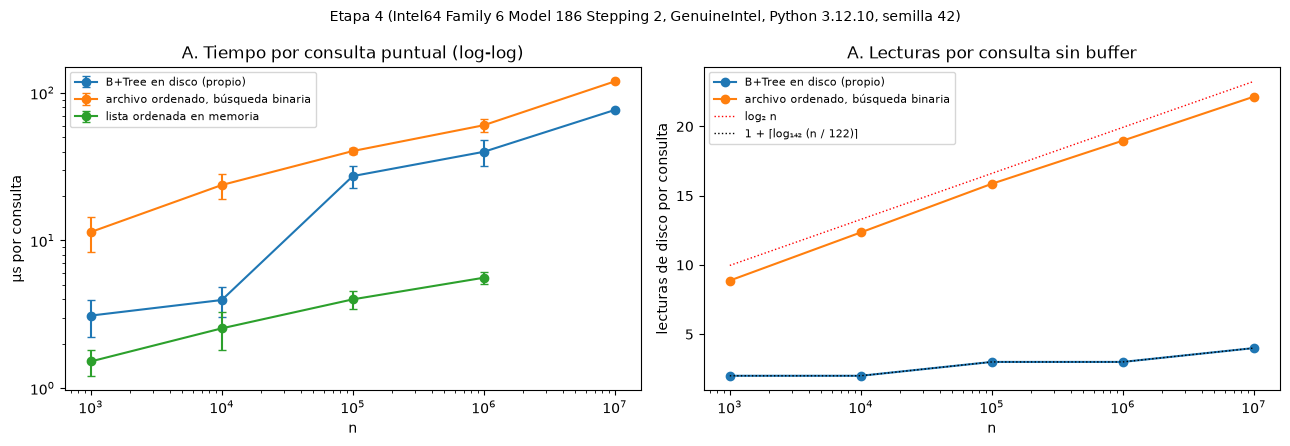

,metodo,n,us_por_consulta,desv_us,lecturas_por_consulta,altura,repeticiones
0,B+Tree en disco (propio),1000,3.10,0.88,2.00,2,100
1,B+Tree en disco (propio),10000,3.95,0.92,2.00,2,100
2,B+Tree en disco (propio),100000,27.28,4.77,3.00,3,20
3,B+Tree en disco (propio),1000000,39.84,7.73,3.00,3,5
4,B+Tree en disco (propio),10000000,76.52,NaN,4.00,4,1
5,"archivo ordenado, búsqueda binaria",1000,11.40,3.02,8.88,2,100
6,"archivo ordenado, búsqueda binaria",10000,23.74,4.60,12.35,2,100
7,"archivo ordenado, búsqueda binaria",100000,40.32,2.05,15.86,3,20
8,"archivo ordenado, búsqueda binaria",1000000,60.31,6.31,18.98,3,5
9,"archivo ordenado, búsqueda binaria",10000000,119.47,NaN,22.15,4,1


,metodo,pendiente_empirica,esperado,rango
0,B+Tree en disco (propio),0.38,≈0 (log_B n),"1,000 a 10,000,000"
1,"archivo ordenado, búsqueda binaria",0.24,≈0 (log₂ n),"1,000 a 10,000,000"
2,lista ordenada en memoria,0.19,≈0 (log₂ n),"1,000 a 1,000,000"


In [8]:
ruta_a = CARPETA_RESULTADOS / "etapa4_consulta_tiempos.csv"
if ruta_a.exists() and not REEJECUTAR_EXPERIMENTOS:
    tiempos_a = pd.read_csv(ruta_a)
    print(f"Resultados leídos de {ruta_a.relative_to(RAIZ)}")
else:
    filas = []
    for n in TAMANOS:
        rng = random.Random(SEED + n)
        arbol_n = construir_arbol(CARPETA_EXPERIMENTOS / "a.bpt", n)
        archivo_n = ArchivoOrdenado(CARPETA_EXPERIMENTOS / "ordenado.bin", n)
        lista_n = ListaOrdenada(n) if n <= LIMITE_MEMORIA else None
        estructuras = [("B+Tree en disco (propio)", arbol_n), ("archivo ordenado, búsqueda binaria", archivo_n)]
        if lista_n is not None:
            estructuras.append(("lista ordenada en memoria", lista_n))

        # Lecturas sin buffer: árbol reabierto con una sola página de buffer
        arbol_n.cerrar()
        arbol_frio = ArbolBMas(CARPETA_EXPERIMENTOS / "a.bpt", capacidad_buffer=1)
        muestra = [entrada_sintetica(rng.randrange(n))[:2] for _ in range(200)]
        consultar(arbol_frio, muestra)
        lecturas_arbol = arbol_frio.lecturas / len(muestra)
        arbol_frio.cerrar()
        archivo_n.lecturas = 0
        consultar(archivo_n, muestra)
        lecturas_archivo = archivo_n.lecturas / len(muestra)
        lecturas = {"B+Tree en disco (propio)": lecturas_arbol, "archivo ordenado, búsqueda binaria": lecturas_archivo,
                    "lista ordenada en memoria": 0.0}

        arbol_n = ArbolBMas(CARPETA_EXPERIMENTOS / "a.bpt")
        estructuras[0] = ("B+Tree en disco (propio)", arbol_n)
        altura = arbol_n.altura
        for rep in range(REPETICIONES[n]):
            consultas = [entrada_sintetica(rng.randrange(n))[:2] for _ in range(CONSULTAS_POR_REPETICION)]
            for nombre, estructura in estructuras:
                filas.append({"metodo": nombre, "n": n, "repeticion": rep, "consultas": len(consultas),
                              "segundos": medir(consultar, estructura, consultas),
                              "lecturas_por_consulta": lecturas[nombre], "altura": altura})
        arbol_n.cerrar()
        archivo_n.cerrar()
        del lista_n, estructuras
        limpiar_experimentos()
        print(f"n = {n:>10,} medido (altura {altura}, {lecturas_arbol:.2f} y {lecturas_archivo:.2f} lecturas por consulta)")
    tiempos_a = pd.DataFrame(filas)
    tiempos_a.to_csv(ruta_a, index=False)
    print(f"Resultados guardados en {ruta_a.relative_to(RAIZ)}")

tiempos_a["us_por_consulta"] = tiempos_a["segundos"] / tiempos_a["consultas"] * 1e6
resumen_a = (tiempos_a.groupby(["metodo", "n"])
             .agg(us_por_consulta=("us_por_consulta", "mean"), desv_us=("us_por_consulta", "std"),
                  lecturas_por_consulta=("lecturas_por_consulta", "first"), altura=("altura", "first"),
                  repeticiones=("segundos", "count"))
             .reset_index())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for nombre, datos in resumen_a.groupby("metodo"):
    ax1.errorbar(datos["n"], datos["us_por_consulta"], yerr=datos["desv_us"], marker="o", capsize=3, label=nombre)
for nombre, datos in resumen_a[resumen_a["metodo"] != "lista ordenada en memoria"].groupby("metodo"):
    ax2.plot(datos["n"], datos["lecturas_por_consulta"], marker="o", label=nombre)
n_ref = np.array(TAMANOS, dtype=float)
ax2.plot(n_ref, np.log2(n_ref), "r:", lw=1, label="log₂ n")
ax2.plot(n_ref, np.ceil(np.log(n_ref / 122) / np.log(142)) + 1, "k:", lw=1, label="1 + ⌈log₁₄₂ (n / 122)⌉")
ax1.set_xscale("log"); ax1.set_yscale("log")
ax1.set_xlabel("n"); ax1.set_ylabel("µs por consulta"); ax1.set_title("A. Tiempo por consulta puntual (log-log)")
ax2.set_xscale("log")
ax2.set_xlabel("n"); ax2.set_ylabel("lecturas de disco por consulta"); ax2.set_title("A. Lecturas por consulta sin buffer")
for ax in (ax1, ax2):
    ax.legend(fontsize=8)
plt.suptitle(f"Etapa 4 ({PLATAFORMA['procesador']}, Python {PLATAFORMA['python']}, semilla {SEED})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "etapa4_consulta.png", dpi=150)
plt.show()

display(resumen_a.round({"us_por_consulta": 2, "desv_us": 2, "lecturas_por_consulta": 2}))
pendientes(resumen_a, "us_por_consulta", {"B+Tree en disco (propio)": "≈0 (log_B n)",
                                          "archivo ordenado, búsqueda binaria": "≈0 (log₂ n)",
                                          "lista ordenada en memoria": "≈0 (log₂ n)"})

### Experimento B. Consulta por rango

Con n = 1M fijo se piden rangos que devuelven k = 10, 100, 1K, 10K y 100K resultados, en posiciones aleatorias. El B+Tree y la lista ordenada deben crecer linealmente con k, con pendiente log-log cercana a 1. El recorrido completo de la lista no depende de k, porque siempre revisa los n elementos. Cada configuración se repite 20 veces.

Resultados leídos de results\etapa4_rango_tiempos.csv


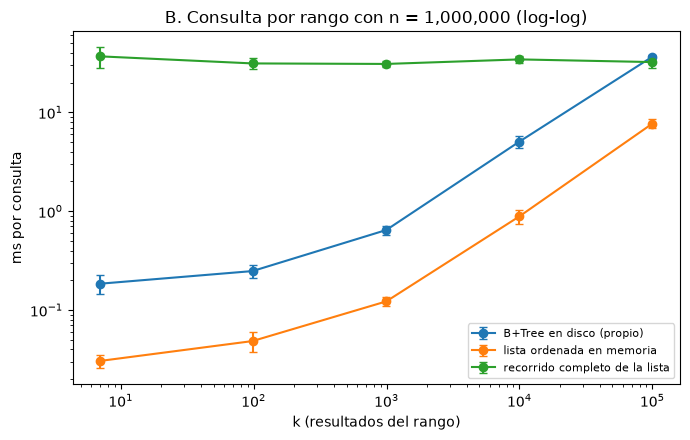

,metodo,k_objetivo,k,ms,desv_ms,lecturas,repeticiones
0,B+Tree en disco (propio),10,7.0,0.185,0.040,1.0,20
1,B+Tree en disco (propio),100,98.0,0.248,0.036,1.9,20
2,B+Tree en disco (propio),1000,994.0,0.644,0.067,9.1,20
3,B+Tree en disco (propio),10000,9996.0,5.055,0.737,83.9,20
4,B+Tree en disco (propio),100000,99995.0,36.491,1.601,821.7,20
5,lista ordenada en memoria,10,7.0,0.031,0.005,0.0,20
6,lista ordenada en memoria,100,98.0,0.049,0.011,0.0,20
7,lista ordenada en memoria,1000,994.0,0.122,0.012,0.0,20
8,lista ordenada en memoria,10000,9996.0,0.887,0.149,0.0,20
9,lista ordenada en memoria,100000,99995.0,7.684,0.806,0.0,20


,metodo,pendiente_empirica,esperado,rango
0,B+Tree en disco (propio),0.57,≈1 (k),"7.0 a 99,995.0"
1,lista ordenada en memoria,0.58,≈1 (k),"7.0 a 99,995.0"
2,recorrido completo de la lista,-0.01,≈0 (n fijo),"7.0 a 99,995.0"


In [9]:
N_RANGO = 1_000_000
RESULTADOS_K = [10, 100, 1_000, 10_000, 100_000]
REPETICIONES_B = 20


def rango_arbol(arbol, desde, hasta):
    return sum(1 for _ in arbol.rango(desde, hasta))


def rango_lista(lista, desde, hasta):
    return len(lista.rango(desde, hasta))


def rango_recorrido(lista, desde, hasta):
    return sum(1 for p, _ in lista.claves if desde <= p <= hasta)


ruta_b = CARPETA_RESULTADOS / "etapa4_rango_tiempos.csv"
if ruta_b.exists() and not REEJECUTAR_EXPERIMENTOS:
    tiempos_b = pd.read_csv(ruta_b)
    print(f"Resultados leídos de {ruta_b.relative_to(RAIZ)}")
else:
    filas = []
    rng = random.Random(SEED)
    arbol_n = construir_arbol(CARPETA_EXPERIMENTOS / "a.bpt", N_RANGO)
    lista_n = ListaOrdenada(N_RANGO)
    for k in RESULTADOS_K:
        for rep in range(REPETICIONES_B):
            # k resultados: k / 7 precios consecutivos, porque cada precio se repite 7 veces
            inicio = rng.randrange(N_RANGO // 7 - k // 7)
            desde, hasta = inicio / 100, (inicio + k // 7 - 1) / 100
            esperado = rango_lista(lista_n, desde, hasta)
            for nombre, funcion, estructura in [("B+Tree en disco (propio)", rango_arbol, arbol_n),
                                                ("lista ordenada en memoria", rango_lista, lista_n),
                                                ("recorrido completo de la lista", rango_recorrido, lista_n)]:
                if nombre.startswith("recorrido") and rep >= 3:
                    continue                                  # O(n) por consulta: 3 repeticiones bastan
                antes = getattr(estructura, "lecturas", 0)
                segundos = medir(funcion, estructura, desde, hasta)
                filas.append({"metodo": nombre, "k": esperado, "k_objetivo": k, "repeticion": rep,
                              "segundos": segundos, "lecturas": getattr(estructura, "lecturas", 0) - antes})
        print(f"k = {k:>7,} medido")
    arbol_n.cerrar()
    del lista_n
    limpiar_experimentos()
    tiempos_b = pd.DataFrame(filas)
    tiempos_b.to_csv(ruta_b, index=False)
    print(f"Resultados guardados en {ruta_b.relative_to(RAIZ)}")

resumen_b = (tiempos_b.groupby(["metodo", "k_objetivo"])
             .agg(k=("k", "mean"), ms=("segundos", lambda s: s.mean() * 1e3), desv_ms=("segundos", lambda s: s.std() * 1e3),
                  lecturas=("lecturas", "mean"), repeticiones=("segundos", "count"))
             .reset_index())

fig, ax = plt.subplots(figsize=(7, 4.5))
for nombre, datos in resumen_b.groupby("metodo"):
    ax.errorbar(datos["k"], datos["ms"], yerr=datos["desv_ms"], marker="o", capsize=3, label=nombre)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("k (resultados del rango)"); ax.set_ylabel("ms por consulta")
ax.set_title(f"B. Consulta por rango con n = {N_RANGO:,} (log-log)"); ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "etapa4_rango.png", dpi=150)
plt.show()

display(resumen_b.round({"k": 0, "ms": 3, "desv_ms": 3, "lecturas": 1}))
pendientes(resumen_b, "ms", {"B+Tree en disco (propio)": "≈1 (k)", "lista ordenada en memoria": "≈1 (k)",
                             "recorrido completo de la lista": "≈0 (n fijo)"}, x="k")

### Experimento C. Construcción

Se compara la carga masiva con n inserciones en orden aleatorio. La carga masiva debe tener pendiente log-log cercana a 1. Las inserciones deben crecer como n log_B n, con pendiente algo mayor que 1, y escribir más páginas, porque cada inserción reescribe su hoja y las divisiones reescriben también el padre. Además se compara la ocupación de las hojas. La carga masiva deja las hojas al 90 %. Con inserciones aleatorias la ocupación esperada es ln 2 ≈ 69 % (Yao, 1978).

Resultados leídos de results\etapa4_construccion_tiempos.csv


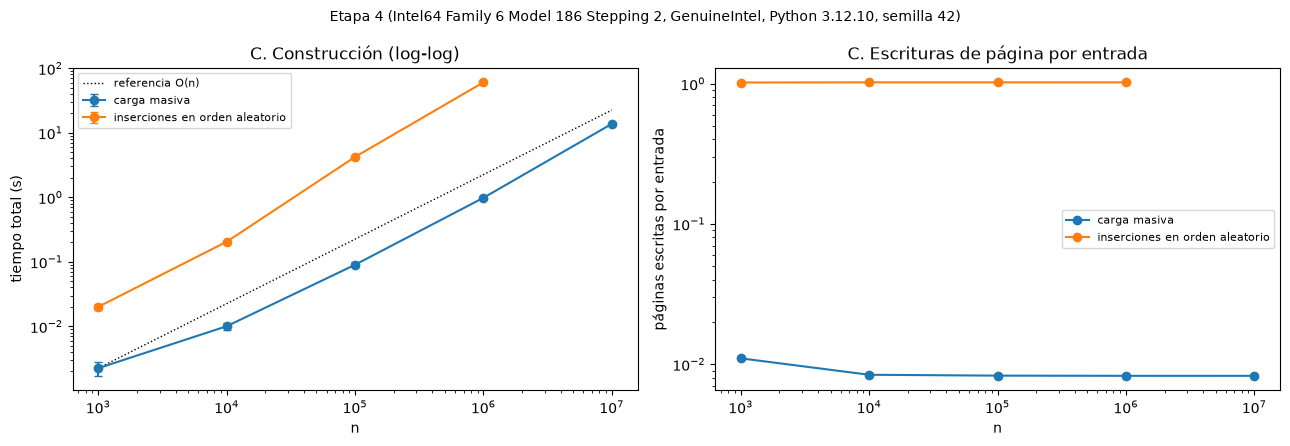

,metodo,n,promedio_s,desv_est_s,paginas_escritas,altura,ocupacion,repeticiones,us_por_entrada,escrituras_por_entrada
0,carga masiva,1000,0.0022,0.0005,11.0,2,0.817,100,2.25,0.0110
1,carga masiva,10000,0.0100,0.0013,84.0,2,0.897,100,1.00,0.0084
2,carga masiva,100000,0.0901,0.0076,828.0,3,0.897,20,0.90,0.0083
3,carga masiva,1000000,0.9820,0.0096,8257.0,3,0.897,5,0.98,0.0083
4,carga masiva,10000000,13.7346,NaN,82553.0,4,0.897,1,1.37,0.0083
5,inserciones en orden aleatorio,1000,0.0201,0.0022,1019.0,2,0.735,20,20.05,1.0190
6,inserciones en orden aleatorio,10000,0.2047,0.0044,10215.0,2,0.681,5,20.47,1.0215
7,inserciones en orden aleatorio,100000,4.2225,0.1843,102151.0,3,0.688,3,42.23,1.0215
8,inserciones en orden aleatorio,1000000,60.4514,NaN,1021645.0,3,0.687,1,60.45,1.0216


,metodo,pendiente_empirica,esperado,rango
0,carga masiva,0.96,≈1 (n),"1,000 a 10,000,000"
1,inserciones en orden aleatorio,1.18,>1 (n log_B n),"1,000 a 1,000,000"


In [10]:
REPETICIONES_MASIVA = REPETICIONES
REPETICIONES_INSERCION = {1_000: 20, 10_000: 5, 100_000: 3, 1_000_000: 1}


def insertar_aleatorio(ruta, orden):
    arbol = ArbolBMas(ruta, crear=True)
    for i in orden:
        arbol.insertar(*entrada_sintetica(i))
    return arbol


ruta_c = CARPETA_RESULTADOS / "etapa4_construccion_tiempos.csv"
if ruta_c.exists() and not REEJECUTAR_EXPERIMENTOS:
    tiempos_c = pd.read_csv(ruta_c)
    print(f"Resultados leídos de {ruta_c.relative_to(RAIZ)}")
else:
    filas = []
    ruta = CARPETA_EXPERIMENTOS / "c.bpt"
    for n in TAMANOS:
        for rep in range(REPETICIONES_MASIVA[n]):
            resultado = {}
            segundos = medir(lambda: resultado.update(arbol=construir_arbol(ruta, n)))
            arbol_n = resultado["arbol"]
            filas.append({"metodo": "carga masiva", "n": n, "repeticion": rep, "segundos": segundos,
                          "paginas_escritas": arbol_n.escrituras, "altura": arbol_n.altura,
                          "ocupacion": arbol_n.ocupacion_hojas() if rep == 0 else None})
            arbol_n.cerrar()
        if n in REPETICIONES_INSERCION:
            orden = list(range(n))
            random.Random(SEED).shuffle(orden)
            for rep in range(REPETICIONES_INSERCION[n]):
                resultado = {}
                segundos = medir(lambda: resultado.update(arbol=insertar_aleatorio(ruta, orden)))
                arbol_n = resultado["arbol"]
                filas.append({"metodo": "inserciones en orden aleatorio", "n": n, "repeticion": rep,
                              "segundos": segundos, "paginas_escritas": arbol_n.escrituras, "altura": arbol_n.altura,
                              "ocupacion": arbol_n.ocupacion_hojas() if rep == 0 else None})
                arbol_n.cerrar()
            del orden
        limpiar_experimentos()
        print(f"n = {n:>10,} medido")
    tiempos_c = pd.DataFrame(filas)
    tiempos_c.to_csv(ruta_c, index=False)
    print(f"Resultados guardados en {ruta_c.relative_to(RAIZ)}")

resumen_c = (tiempos_c.groupby(["metodo", "n"])
             .agg(promedio_s=("segundos", "mean"), desv_est_s=("segundos", "std"),
                  paginas_escritas=("paginas_escritas", "mean"), altura=("altura", "first"),
                  ocupacion=("ocupacion", "first"), repeticiones=("segundos", "count"))
             .reset_index())
resumen_c["us_por_entrada"] = resumen_c["promedio_s"] / resumen_c["n"] * 1e6
resumen_c["escrituras_por_entrada"] = resumen_c["paginas_escritas"] / resumen_c["n"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for nombre, datos in resumen_c.groupby("metodo"):
    ax1.errorbar(datos["n"], datos["promedio_s"], yerr=datos["desv_est_s"], marker="o", capsize=3, label=nombre)
    ax2.plot(datos["n"], datos["escrituras_por_entrada"], marker="o", label=nombre)
base = resumen_c.query("metodo == 'carga masiva'").iloc[0]
n_ref = np.array(TAMANOS, dtype=float)
ax1.plot(n_ref, base["promedio_s"] * n_ref / base["n"], "k:", lw=1, label="referencia O(n)")
ax1.set_xscale("log"); ax1.set_yscale("log")
ax1.set_xlabel("n"); ax1.set_ylabel("tiempo total (s)"); ax1.set_title("C. Construcción (log-log)")
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xlabel("n"); ax2.set_ylabel("páginas escritas por entrada"); ax2.set_title("C. Escrituras de página por entrada")
for ax in (ax1, ax2):
    ax.legend(fontsize=8)
plt.suptitle(f"Etapa 4 ({PLATAFORMA['procesador']}, Python {PLATAFORMA['python']}, semilla {SEED})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "etapa4_construccion.png", dpi=150)
plt.show()

display(resumen_c.round({"promedio_s": 4, "desv_est_s": 4, "paginas_escritas": 0, "ocupacion": 3,
                         "us_por_entrada": 2, "escrituras_por_entrada": 4}))
pendientes(resumen_c, "promedio_s", {"carga masiva": "≈1 (n)", "inserciones en orden aleatorio": ">1 (n log_B n)"})

### Experimento D. Tamaño de página

Con n = 1M fijo se construye el árbol con páginas de 256 B a 16 KB. Una página más grande admite más claves por nodo (B mayor) y reduce la altura y las lecturas por consulta. A cambio, cada página leída tiene más bytes que transferir y decodificar. Se miden la altura, las lecturas y el tiempo por consulta sin buffer (buffer pool de una página), y el tamaño del archivo. Cada tamaño se mide con 5 repeticiones de 1 000 consultas.

Resultados leídos de results\etapa4_pagina.csv


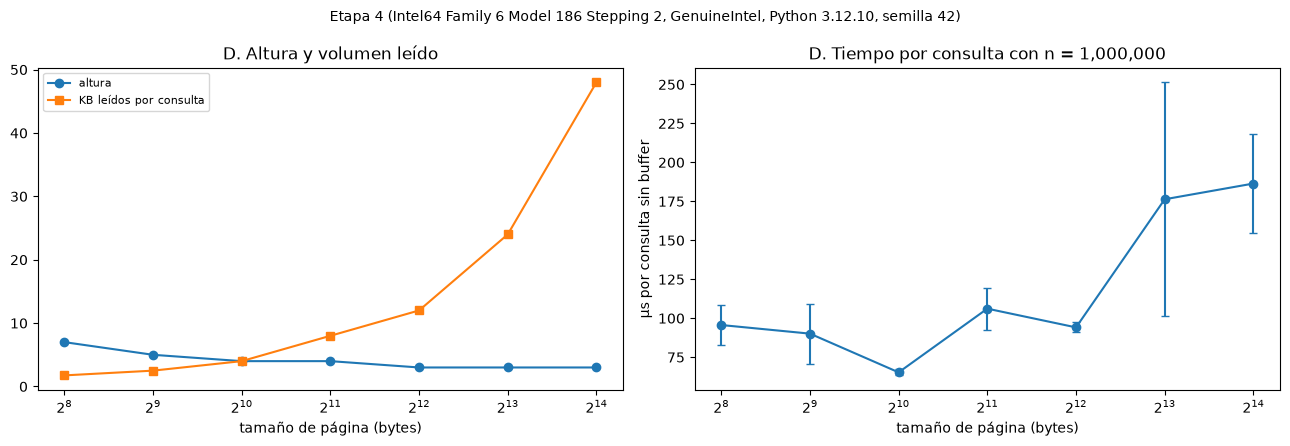

,tam_pagina,claves_por_interno,altura,lecturas_por_consulta,us_por_consulta,desv_us,mb_archivo,kb_leidos_por_consulta
0,256,9,7,7.0,95.7,13.1,41.1,1.8
1,512,19,5,5.0,90.1,19.3,38.7,2.5
2,1024,38,4,4.0,65.3,1.9,36.4,4.0
3,2048,78,4,4.0,106.2,13.5,34.6,8.0
4,4096,157,3,3.0,94.1,3.2,33.8,12.0
5,8192,314,3,3.0,176.3,75.0,33.7,24.0
6,16384,629,3,3.0,186.4,31.7,33.5,48.0


In [11]:
TAMANOS_PAGINA = [256, 512, 1024, 2048, 4096, 8192, 16384]
N_PAGINA = 1_000_000
REPETICIONES_D = 5

ruta_d = CARPETA_RESULTADOS / "etapa4_pagina.csv"
if ruta_d.exists() and not REEJECUTAR_EXPERIMENTOS:
    tiempos_d = pd.read_csv(ruta_d)
    print(f"Resultados leídos de {ruta_d.relative_to(RAIZ)}")
else:
    filas = []
    rng = random.Random(SEED)
    ruta = CARPETA_EXPERIMENTOS / "d.bpt"
    for tam in TAMANOS_PAGINA:
        construir_arbol(ruta, N_PAGINA, tam_pagina=tam).cerrar()
        arbol_n = ArbolBMas(ruta, capacidad_buffer=1)
        for rep in range(REPETICIONES_D):
            consultas = [entrada_sintetica(rng.randrange(N_PAGINA))[:2] for _ in range(CONSULTAS_POR_REPETICION)]
            antes = arbol_n.lecturas
            segundos = medir(consultar, arbol_n, consultas)
            filas.append({"tam_pagina": tam, "repeticion": rep, "segundos": segundos,
                          "lecturas_por_consulta": (arbol_n.lecturas - antes) / len(consultas),
                          "altura": arbol_n.altura, "claves_por_hoja": arbol_n.max_hoja,
                          "claves_por_interno": arbol_n.max_interno, "mb_archivo": arbol_n.tamano_bytes() / 1e6})
        arbol_n.cerrar()
        limpiar_experimentos()
        print(f"página de {tam:>6,} bytes medida")
    tiempos_d = pd.DataFrame(filas)
    tiempos_d.to_csv(ruta_d, index=False)
    print(f"Resultados guardados en {ruta_d.relative_to(RAIZ)}")

tiempos_d["us_por_consulta"] = tiempos_d["segundos"] / CONSULTAS_POR_REPETICION * 1e6
resumen_d = (tiempos_d.groupby("tam_pagina")
             .agg(claves_por_interno=("claves_por_interno", "first"), altura=("altura", "first"),
                  lecturas_por_consulta=("lecturas_por_consulta", "mean"), us_por_consulta=("us_por_consulta", "mean"),
                  desv_us=("us_por_consulta", "std"), mb_archivo=("mb_archivo", "first"))
             .reset_index())
resumen_d["kb_leidos_por_consulta"] = resumen_d["lecturas_por_consulta"] * resumen_d["tam_pagina"] / 1024

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(resumen_d["tam_pagina"], resumen_d["altura"], marker="o", label="altura")
ax1.plot(resumen_d["tam_pagina"], resumen_d["kb_leidos_por_consulta"], marker="s", label="KB leídos por consulta")
ax1.set_xscale("log", base=2); ax1.set_xlabel("tamaño de página (bytes)"); ax1.set_title("D. Altura y volumen leído")
ax1.legend(fontsize=8)
ax2.errorbar(resumen_d["tam_pagina"], resumen_d["us_por_consulta"], yerr=resumen_d["desv_us"], marker="o", capsize=3)
ax2.set_xscale("log", base=2); ax2.set_xlabel("tamaño de página (bytes)"); ax2.set_ylabel("µs por consulta sin buffer")
ax2.set_title(f"D. Tiempo por consulta con n = {N_PAGINA:,}")
plt.suptitle(f"Etapa 4 ({PLATAFORMA['procesador']}, Python {PLATAFORMA['python']}, semilla {SEED})", fontsize=10)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "etapa4_pagina.png", dpi=150)
plt.show()

resumen_d.round({"lecturas_por_consulta": 2, "us_por_consulta": 1, "desv_us": 1, "mb_archivo": 1,
                 "kb_leidos_por_consulta": 1})

### Memoria

Se mide con `tracemalloc` la memoria actual (lo que queda ocupado después de abrir cada estructura y hacer 1 000 consultas) y la memoria pico (el máximo durante ese proceso). El B+Tree en disco solo mantiene en memoria su buffer pool, así que su memoria no debe depender de n. La lista ordenada guarda todas las claves en memoria y debe crecer linealmente con n.

In [12]:
ruta_memoria = CARPETA_RESULTADOS / "etapa4_memoria.csv"
if ruta_memoria.exists() and not REEJECUTAR_EXPERIMENTOS:
    memoria = pd.read_csv(ruta_memoria)
else:
    filas = []
    for n in [1_000, 10_000, 100_000, 1_000_000]:
        construir_arbol(CARPETA_EXPERIMENTOS / "m.bpt", n).cerrar()
        consultas = [entrada_sintetica(i)[:2] for i in random.Random(SEED).sample(range(n), 1_000)]
        for nombre, abrir in [("B+Tree en disco (propio)", lambda: ArbolBMas(CARPETA_EXPERIMENTOS / "m.bpt")),
                              ("lista ordenada en memoria", lambda: ListaOrdenada(n))]:
            gc.collect()
            tracemalloc.start()
            estructura = abrir()
            consultar(estructura, consultas)
            actual, pico = tracemalloc.get_traced_memory()
            tracemalloc.stop()
            filas.append({"metodo": nombre, "n": n, "actual_mb": actual / 1e6, "pico_mb": pico / 1e6})
            if hasattr(estructura, "cerrar"):
                estructura.cerrar()
            del estructura
        limpiar_experimentos()
    memoria = pd.DataFrame(filas)
    memoria.to_csv(ruta_memoria, index=False)

memoria.pivot(index="n", columns="metodo", values=["actual_mb", "pico_mb"]).round(2)

actual_mb                            \
metodo  B+Tree en disco (propio) lista ordenada en memoria   
n                                                            
1000                        0.26                      0.23   
10000                       2.34                      2.28   
100000                      7.20                     22.70   
1000000                     7.03                    227.90   

                         pico_mb                            
metodo  B+Tree en disco (propio) lista ordenada en memoria  
n                                                           
1000                        0.26                      0.23  
10000                       2.35                      2.28  
100000                      7.22                     22.70  
1000000                     7.05                    227.90

### Lectura de los resultados

Los valores citados corresponden a la ejecución guardada en `results/`. Al medir de nuevo pueden variar ligeramente.

- **Índice de precios.** Con 282 534 entradas el árbol tiene altura 3, que es la mínima posible, y las hojas quedan al 89.7 % de ocupación. Las 53 881 inserciones de productos con precio observado en el stream cuestan 74 µs cada una, dividen 922 páginas y no cambian la altura, porque el 10 % libre de la carga masiva absorbe la mayor parte. El índice queda con 336 415 entradas.
- **Experimento A, lecturas.** Sin buffer, el B+Tree lee exactamente una página por nivel, 2 lecturas a 1K y 4 a 10M. El archivo ordenado lee entre 8.9 y 22.2 registros, como log₂ n. A 10M el B+Tree hace 5.5 veces menos lecturas. Esta es la ventaja que justifica el B+Tree en disco, porque en un disco real cada lectura cuesta mucho más que una comparación en memoria.
- **Experimento A, tiempo.** El B+Tree es entre 1.5 y 3.7 veces más rápido que el archivo ordenado en todos los tamaños. Su tiempo salta de 4 µs a 10K a 27 µs a 100K. A 10K el árbol completo tiene unas 85 páginas y cabe en el buffer pool de 256 páginas. Desde 100K la mayoría de las hojas se leen del disco y se decodifican en cada consulta. Por eso su pendiente (0.38) es mayor que la que predice log_B n. Los dos métodos en disco se benefician de la caché de páginas del sistema operativo, así que las diferencias en tiempo son menores que las diferencias en lecturas. La lista en memoria es la más rápida (1.5 a 5.6 µs), pero ocupa memoria proporcional a n.
- **Experimento B.** Para rangos pequeños el B+Tree responde en 0.19 ms, 200 veces menos que el recorrido completo de la lista (37 ms). El costo crece con k. Entre k = 1 000 y k = 100 000 la pendiente es 0.88 para el B+Tree y 0.90 para la lista. La pendiente global (0.57) es menor porque con k pequeño domina el costo fijo del descenso. Las lecturas siguen la fórmula altura + k / 122, con 822 páginas para k = 100 000. Con k = 100 000, el 10 % de n, el B+Tree (36 ms) ya tarda lo mismo que el recorrido completo (32 ms). Para rangos que cubren una fracción grande de los datos un índice deja de ser ventajoso.
- **Experimento C.** La carga masiva tiene pendiente 0.96 y cuesta alrededor de 1 µs por entrada en todo el rango, con 0.008 páginas escritas por entrada. Las inserciones en orden aleatorio tienen pendiente 1.18, coherente con n log_B n más el efecto de las hojas que no caben en el buffer pool. Cuestan de 20 a 60 µs por entrada y escriben 1.02 páginas por entrada, 123 veces más que la carga masiva. La ocupación de las hojas con inserciones aleatorias es 68.7 %, muy cerca del ln 2 = 69.3 % que predice Yao (1978). La carga masiva deja 89.7 %.
- **Experimento D.** La altura baja de 7 con páginas de 256 B a 3 con páginas de 4 KB o más. El volumen leído por consulta sube de 1.8 KB a 48 KB. En tiempo el mínimo está en 1 KB (65 µs) y con 8 KB y 16 KB el tiempo se duplica, porque en Python decodificar una página grande cuesta más que leerla de la caché del sistema operativo. Se mantienen las páginas de 4 KB porque coinciden con el tamaño de página del sistema operativo y del bloque de un SSD, dan altura 3 hasta unos 2.8 millones de entradas y su tiempo está dentro de la variación de los tamaños vecinos.
- **Memoria.** El B+Tree ocupa unos 7 MB desde 100K, que es su buffer pool lleno, y no crece con n. Su pico es casi igual a la memoria actual, porque el buffer pool reemplaza páginas sin acumularlas. La lista ordenada crece linealmente y llega a 228 MB con 1M, 32 veces más.

El B+Tree cumple las complejidades teóricas en número de lecturas, que es la medida relevante para un índice en disco. La carga masiva es la forma adecuada de construirlo desde el catálogo, y la inserción en línea es suficiente para las actualizaciones del stream.

## Paso 7. Salida de la etapa 4

La salida es el archivo del índice, `data/interim/<CATEGORIA>/etapa4_indice_precio.bpt`. Se abre con `ArbolBMas(RUTA_INDICE_PRECIO)` y no hace falta reconstruirlo.

| Etapa | Uso |
| --- | --- |
| 5. KD-Tree y KNN | Restringir la búsqueda de productos similares a un rango de precio |
| 9. Servicio | Listados y filtros del panel por rango de precio, combinados con la disponibilidad de la etapa 3 |

In [13]:
arbol.cerrar()
catalogo.close()
almacen.cerrar()
shutil.rmtree(CARPETA_EXPERIMENTOS, ignore_errors=True)

with ArbolBMas(RUTA_INDICE_PRECIO) as indice:
    print(f"{RUTA_INDICE_PRECIO.relative_to(RAIZ)}: {RUTA_INDICE_PRECIO.stat().st_size / 1e6:.1f} MB, "
          f"{len(indice):,} entradas, altura {indice.altura}")
    ejemplo = list(indice.rango(19.99, 19.99))
print(f"Productos a 19.99 dólares: {len(ejemplo):,}")

data\interim\Office_Products\etapa4_indice_precio.bpt: 13.3 MB, 336,415 entradas, altura 3
Productos a 19.99 dólares: 4,717


## Resumen de la etapa 4

| Aspecto | Decisión |
| --- | --- |
| Estructura | B+Tree propio en un archivo de páginas de 4 096 bytes, con hojas enlazadas |
| Clave y valor | `(precio, parent_asin)` → `(offset, largo)` del registro en el catálogo de la etapa 3 |
| Capacidad | 136 entradas por hoja y 157 claves por nodo interno |
| Construcción | Merge sort de la etapa 1 y carga masiva al 90 % en O(n). Inserción en línea con división de nodos para los precios observados en el stream |
| Buffer pool | `CacheLRU` de la etapa 3 con 256 páginas. Escrituras inmediatas en disco |
| Eliminación | Sin fusión de nodos |
| Salida | `data/interim/<CATEGORIA>/etapa4_indice_precio.bpt` |

Referencias. Bayer, R., y McCreight, E. (1972). Organization and maintenance of large ordered indexes. *Acta Informatica*, 1(3), 173-189. Comer, D. (1979). The ubiquitous B-tree. *ACM Computing Surveys*, 11(2), 121-137. Yao, A. C. (1978). On random 2-3 trees. *Acta Informatica*, 9(2), 159-170. Cormen, T. H., Leiserson, C. E., Rivest, R. L., y Stein, C. (2022). *Introduction to Algorithms* (4.ª ed.), cap. 18.